# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [2]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 streamlit==1.43.2 PyGithub==2.6.1 -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> pandas

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [3]:
# Install PyGithub dynamically if it's missing
try:
    from github import Github
except ImportError:
    import subprocess
    import sys
    print("Installing missing dependency: PyGithub...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "PyGithub"])
    from github import Github

# for data manipulation
import pandas as pd

import sklearn

# for data preprocessing and pipeline creation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

# for model training, tuning, and evaluation
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, recall_score

# for model serialization
import joblib

# for creating a folder
import os

Installing missing dependency: PyGithub...


# **Loading the dataset**

**Input required:** place the course-provided `SuperKart.csv` in the same working directory as this notebook. The training data is not embedded in the notebook.


In [4]:
# Load the training dataset. Place SuperKart.csv beside this notebook.
DATA_PATH = "SuperKart.csv"
if not os.path.exists(DATA_PATH):
    matches = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "superkart" in f.lower() and "batch" not in f.lower()]
    if matches: DATA_PATH = matches[0]
    else: raise FileNotFoundError("Upload SuperKart.csv to the notebook working directory; the dataset is not embedded in this notebook.")
data = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}: {data.shape[0]:,} rows x {data.shape[1]} columns")
display(data.head())


Loaded SuperKart.csv: 8,763 rows x 12 columns


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# **Data Overview**

In [5]:
print("Shape:", data.shape)
display(data.head())
display(data.sample(min(5, len(data)), random_state=42))
data.info()
display(data.describe(include="all").T)
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Duplicate rows:", data.duplicated().sum())


Shape: (8763, 12)


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
1226,FD1781,12.53,Regular,0.066,Snack Foods,145.62,OUT004,2009,Medium,Tier 2,Supermarket Type2,3396.37
7903,FD3171,13.29,Low Sugar,0.086,Canned,135.99,OUT004,2009,Medium,Tier 2,Supermarket Type2,3371.45
1559,FD1479,9.99,Regular,0.090,Fruits and Vegetables,125.79,OUT001,1987,High,Tier 2,Supermarket Type1,2416.69
3621,NC4402,10.72,No Sugar,0.049,Health and Hygiene,92.94,OUT002,1998,Small,Tier 3,Food Mart,1910.53
7552,DR433,15.60,Low Sugar,0.121,Soft Drinks,176.07,OUT001,1987,High,Tier 2,Supermarket Type1,3191.08


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


Duplicate rows: 0


# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

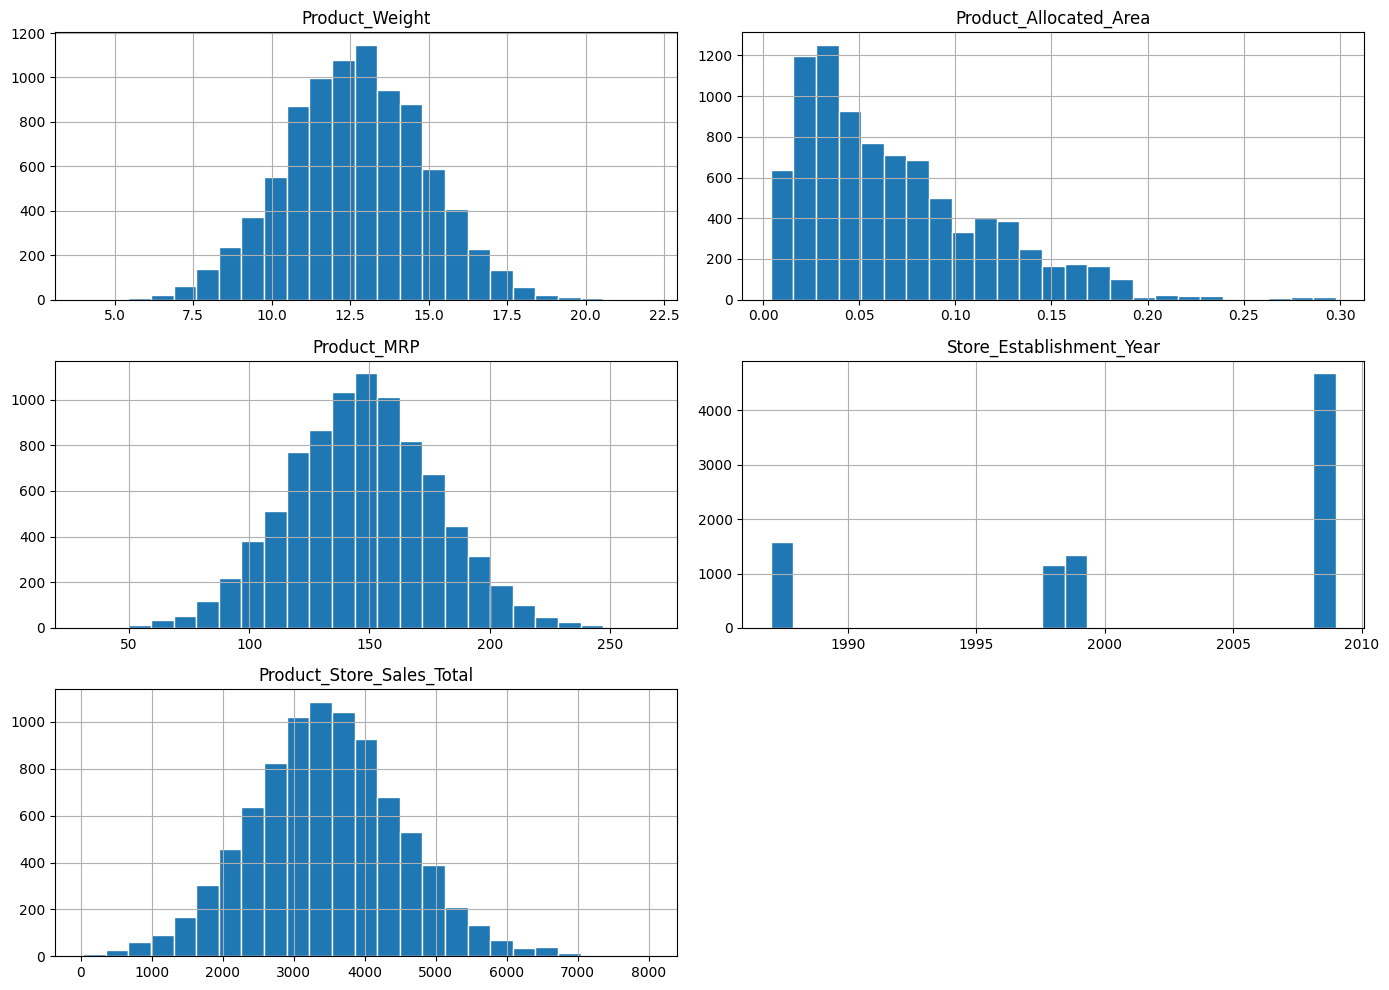

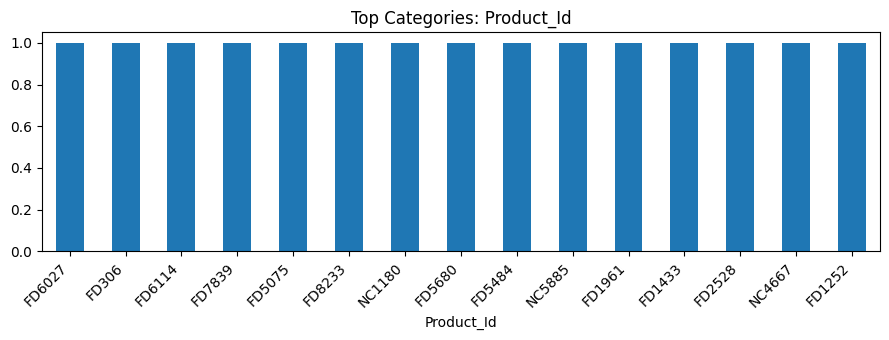

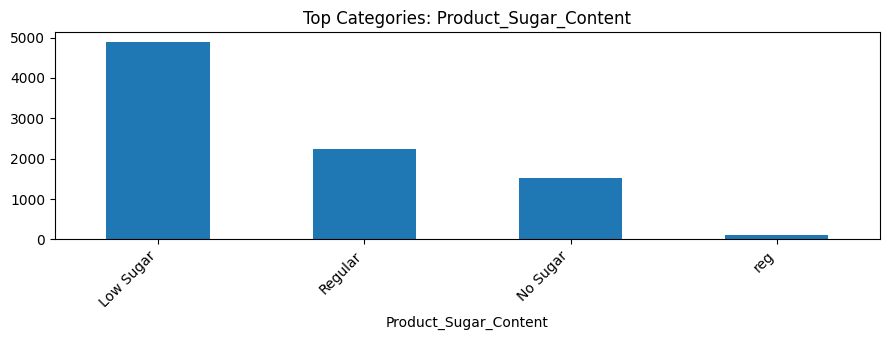

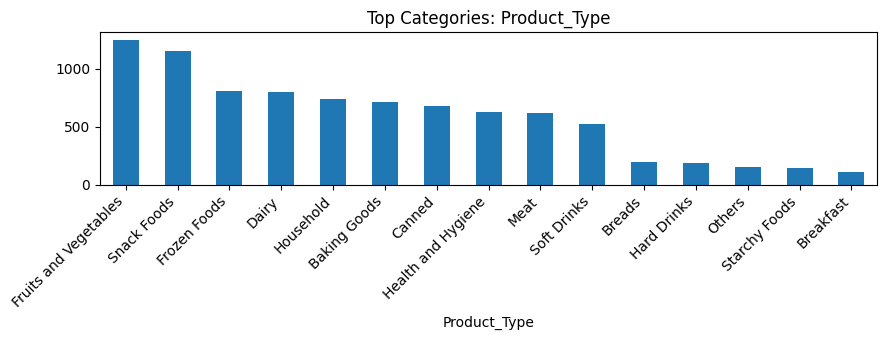

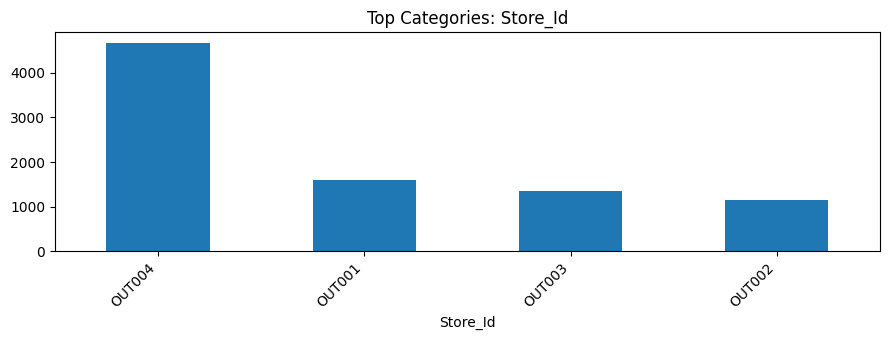

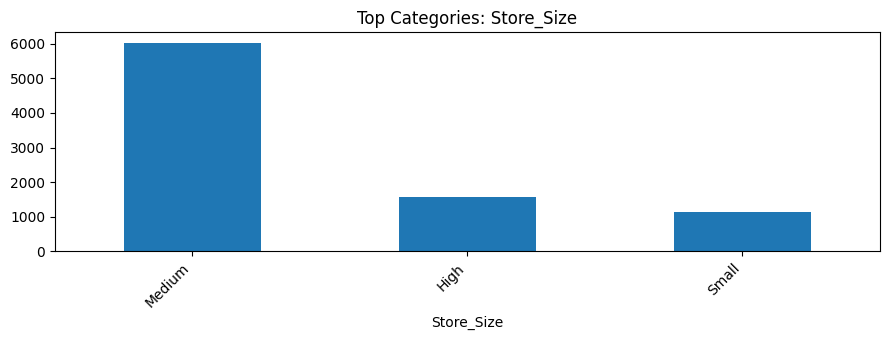

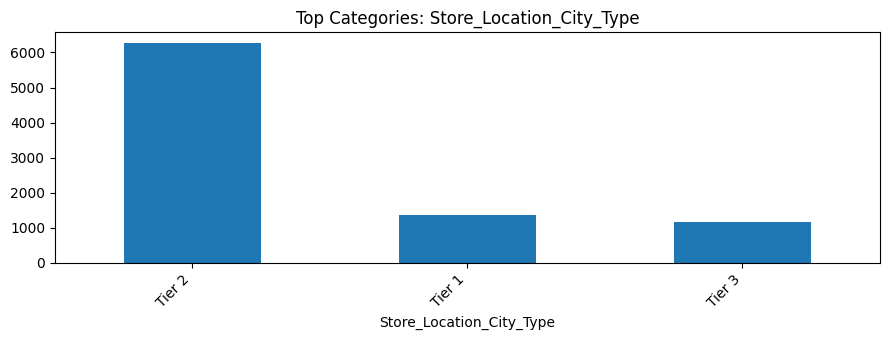

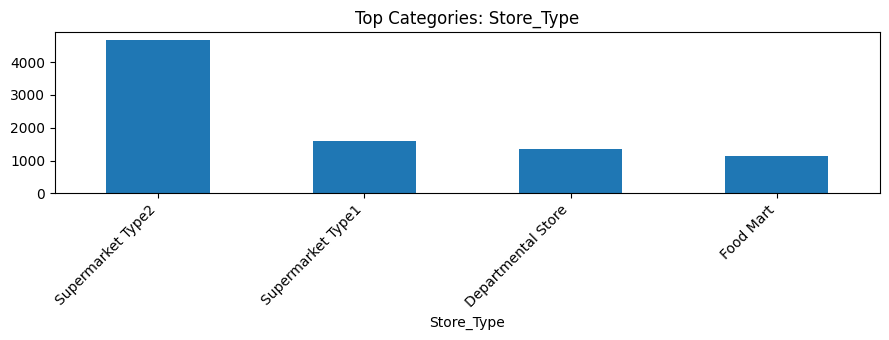

In [6]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    data[numeric_cols].hist(figsize=(14, 10), bins=25, edgecolor="white")
    plt.tight_layout()
    plt.show()
for col in data.select_dtypes(exclude=np.number).columns:
    plt.figure(figsize=(9, 3.5))
    data[col].astype("string").value_counts().head(15).plot(kind="bar")
    plt.title(f"Top Categories: {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## Bivariate Analysis

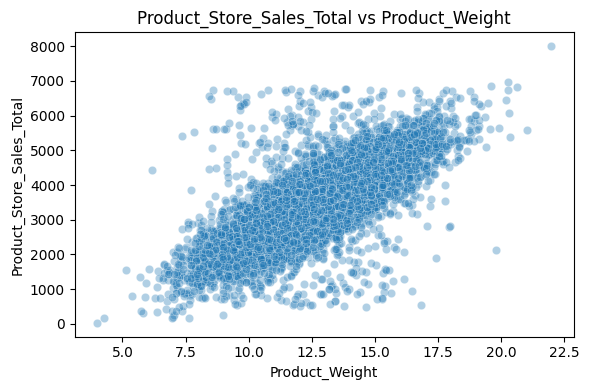

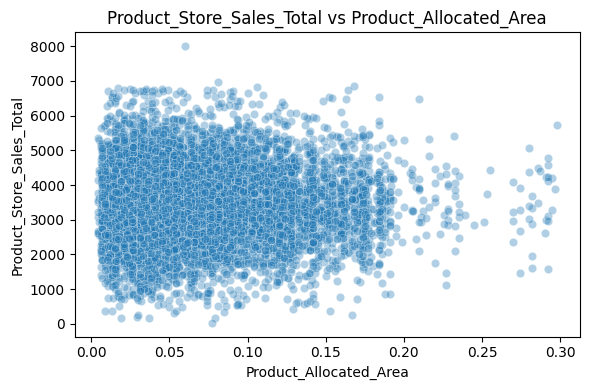

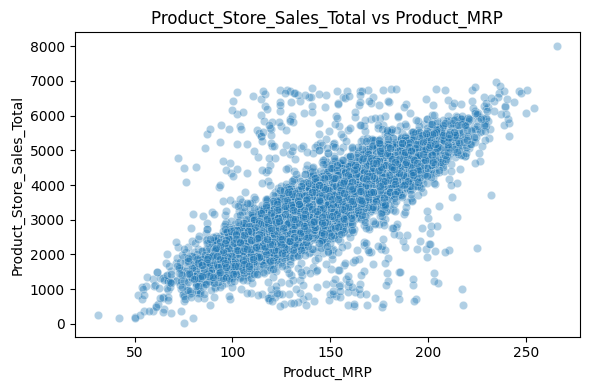

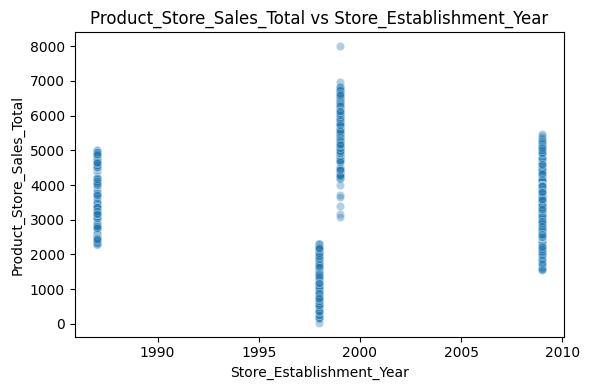

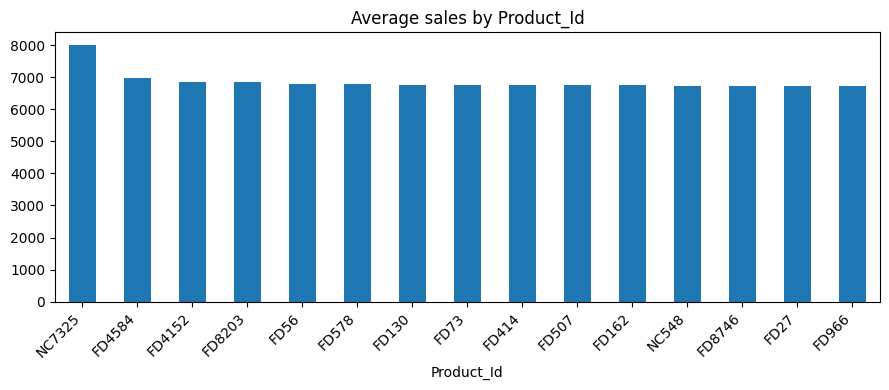

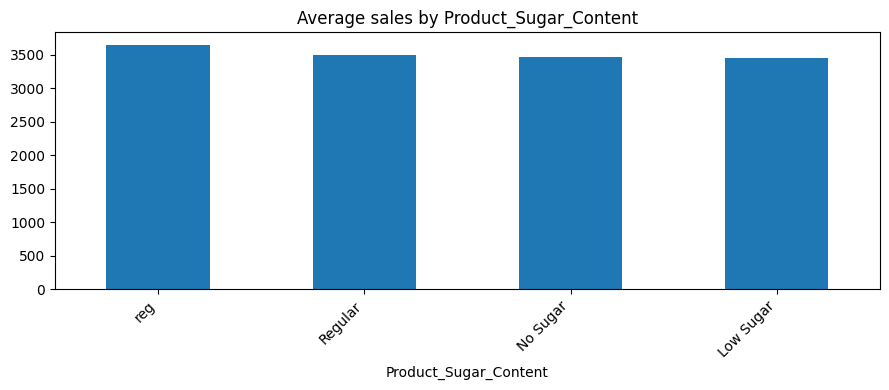

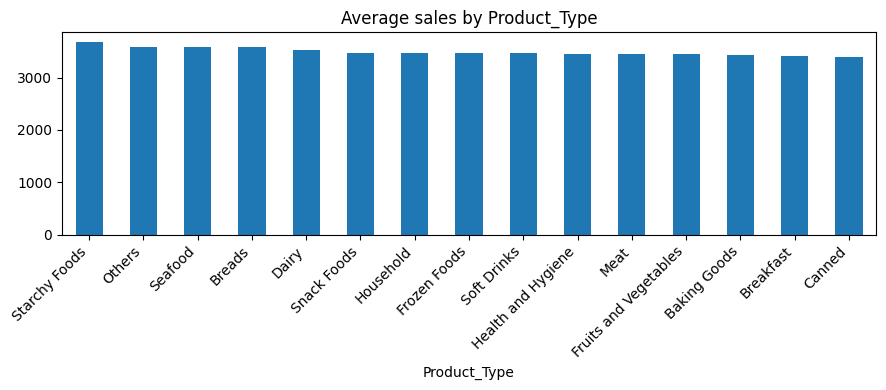

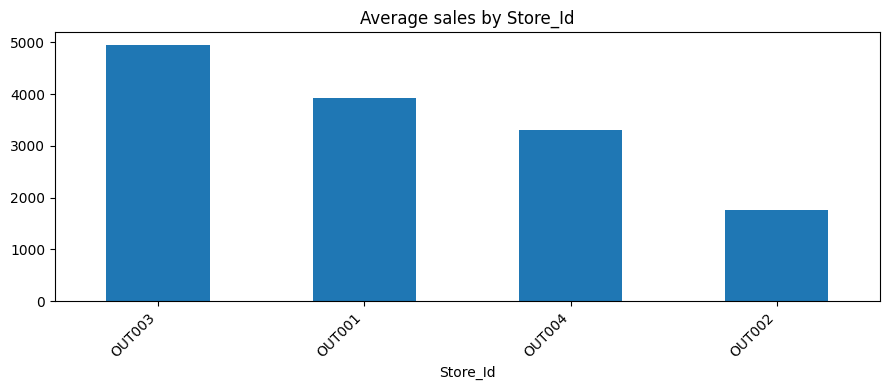

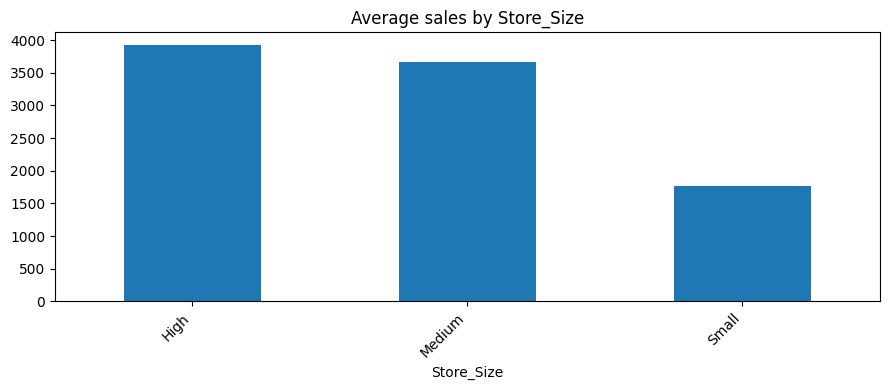

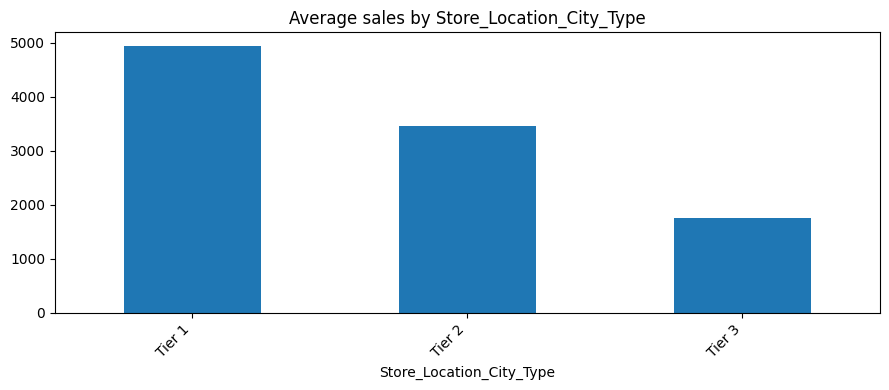

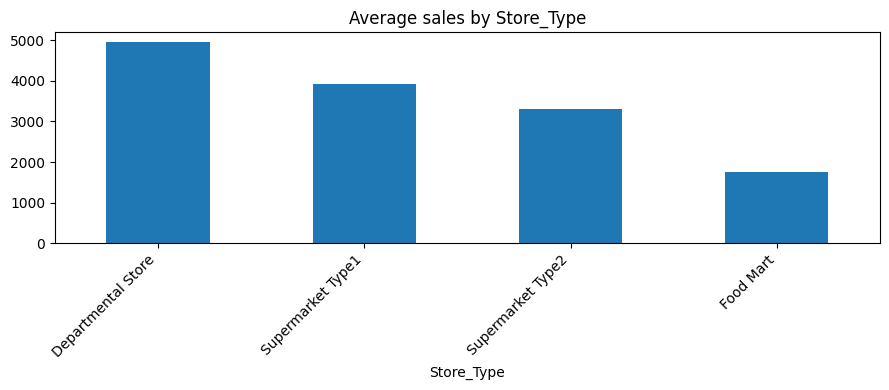

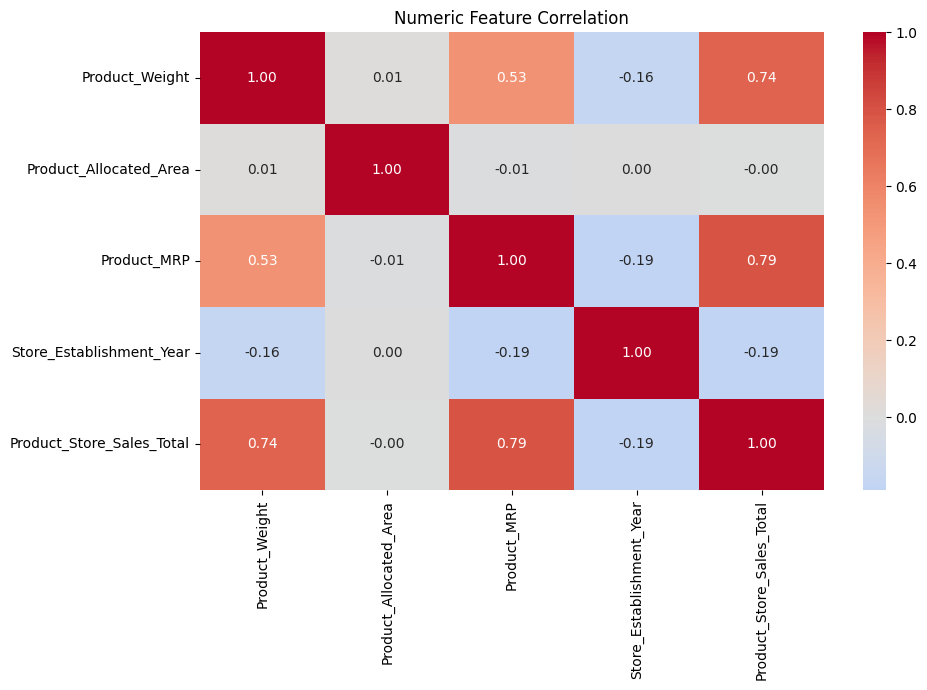

In [7]:
target_col = "Product_Store_Sales_Total"
if target_col not in data.columns: raise KeyError(f"Expected target column {target_col!r}; found {list(data.columns)}")
for col in data.select_dtypes(include=np.number).columns:
    if col != target_col:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=data, x=col, y=target_col, alpha=.35)
        plt.title(f"{target_col} vs {col}")
        plt.tight_layout(); plt.show()
for col in data.select_dtypes(exclude=np.number).columns:
    summary = data.groupby(col, dropna=False)[target_col].mean().sort_values(ascending=False).head(15)
    plt.figure(figsize=(9, 4)); summary.plot(kind="bar")
    plt.title(f"Average sales by {col}"); plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()
plt.figure(figsize=(10, 7))
sns.heatmap(data.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation"); plt.tight_layout(); plt.show()


# **Data Preprocessing**

In [8]:
from sklearn.impute import SimpleImputer

target_col = "Product_Store_Sales_Total"
required = {target_col, "Product_Id", "Store_Establishment_Year"}
missing = required - set(data.columns)
if missing: raise KeyError(f"Missing required columns: {sorted(missing)}")
model_data = data.copy()
model_data["Product_Id_char"] = model_data["Product_Id"].astype("string").str[:2].fillna("Unknown")
model_data["Store_Age_Years"] = pd.Timestamp.today().year - pd.to_numeric(model_data["Store_Establishment_Year"], errors="coerce")
def product_type_category(value):
    value = str(value).strip().lower()
    if value in {"meat", "seafood", "fruits and vegetables", "dairy", "frozen foods", "bread", "breakfast"}: return "Perishables"
    if value in {"health and hygiene", "household"}: return "Non Consumables"
    return "Non Perishables"
if "Product_Type" in model_data.columns:
    model_data["Product_Type_Category"] = model_data["Product_Type"].map(product_type_category)
drop_cols = [c for c in ["Product_Id", "Store_Id", "Store_Establishment_Year", "Product_Type"] if c in model_data.columns]
X = model_data.drop(columns=drop_cols + [target_col])
y = pd.to_numeric(model_data[target_col], errors="coerce")
valid = y.notna()
X, y = X.loc[valid].copy(), y.loc[valid].copy()
not_empty = ~X.isna().all(axis=1)
X, y = X.loc[not_empty], y.loc[not_empty]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_transformer = make_pipeline(SimpleImputer(strategy="median"))
categorical_transformer = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
preprocessor = make_column_transformer((numeric_transformer, numeric_features), (categorical_transformer, categorical_features), remainder="drop")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Train/test:", X_train.shape, X_test.shape)


Numeric features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Age_Years']
Categorical features: ['Product_Sugar_Content', 'Store_Size', 'Store_Location_City_Type', 'Store_Type', 'Product_Id_char', 'Product_Type_Category']
Train/test: (7010, 10) (1753, 10)


# **Model Building**

## Define functions for Model Evaluation

In [9]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

In [10]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
baseline_pipelines, rows = {}, []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    baseline_pipelines[name] = pipe
    metrics = model_performance_regression(pipe, X_test, y_test)
    metrics.insert(0, "Model", name)
    rows.append(metrics)
baseline_comparison = pd.concat(rows, ignore_index=True).sort_values("RMSE")
display(baseline_comparison)


,Model,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,Random Forest,279.185972,105.975540,0.931688,0.931296,0.037910
1,Gradient Boosting,313.444133,147.629012,0.913895,0.913401,0.052117


# **Model Performance Improvement - Hyperparameter Tuning**

In [11]:
rf_pipeline = Pipeline([("preprocessor", preprocessor), ("model", RandomForestRegressor(random_state=42, n_jobs=-1))])
param_grid = {"model__n_estimators": [150, 250], "model__max_depth": [None, 15], "model__min_samples_leaf": [1, 2]}
grid_search = GridSearchCV(rf_pipeline, param_grid, scoring="neg_root_mean_squared_error", cv=3, n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)
best_tuned_model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)
display(model_performance_regression(best_tuned_model, X_test, y_test))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 250}
Best CV RMSE: 286.7155695076619


,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,279.185972,105.97554,0.931688,0.931296,0.03791


# **Model Performance Comparison, Final Model Selection, and Serialization**

In [12]:
rows = []
for name, pipe in baseline_pipelines.items():
    metrics = model_performance_regression(pipe, X_test, y_test)
    metrics.insert(0, "Model", name); rows.append(metrics)
metrics = model_performance_regression(best_tuned_model, X_test, y_test)
metrics.insert(0, "Model", "Tuned Random Forest"); rows.append(metrics)
model_comparison = pd.concat(rows, ignore_index=True).sort_values("RMSE").reset_index(drop=True)
display(model_comparison)
best_name = model_comparison.loc[0, "Model"]
final_model = best_tuned_model if best_name == "Tuned Random Forest" else baseline_pipelines[best_name]
os.makedirs("backend_files", exist_ok=True)
joblib.dump(final_model, "backend_files/superkart_model.joblib")
print(f"Selected model: {best_name}")
print("Serialized model: backend_files/superkart_model.joblib")


,Model,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,Random Forest,279.185972,105.975540,0.931688,0.931296,0.037910
1,Tuned Random Forest,279.185972,105.975540,0.931688,0.931296,0.037910
2,Gradient Boosting,313.444133,147.629012,0.913895,0.913401,0.052117


Selected model: Random Forest
Serialized model: backend_files/superkart_model.joblib


# **Deployment - Backend**

## Points to note before executing the below cells
- Create a GitHub account if you don't already have one at [github.com](https://github.com)
- Generate a **Personal Access Token**
  - Make sure the token has **repo** scope (full control of private repositories)
- The serialized ML model file (`superkart_model.joblib`) should already be present in the `backend_files` folder before pushing to GitHub
- We will deploy **both the Flask backend and the Streamlit frontend as separate Docker containers** inside a GitHub Codespace, and connect them using a **Docker network**

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [13]:
import os
os.makedirs('backend_files', exist_ok=True)
backend_code = "from flask import Flask, request, jsonify\nimport joblib, pandas as pd, numpy as np\napp = Flask(__name__)\nmodel = joblib.load('superkart_model.joblib')\nFEATURES = ['Product_Weight','Product_Sugar_Content','Product_Allocated_Area','Product_MRP','Store_Size','Store_Location_City_Type','Store_Type','Product_Id_char','Store_Age_Years','Product_Type_Category']\ndef prepare(frame):\n    for col in FEATURES:\n        if col not in frame.columns: frame[col] = np.nan\n    return frame[FEATURES]\n@app.get('/health')\ndef health(): return jsonify({'status':'ok'})\n@app.post('/v1/predict')\ndef predict():\n    payload = request.get_json(silent=True)\n    if not isinstance(payload, dict): return jsonify({'error':'Send a JSON object.'}), 400\n    try: return jsonify({'predicted_sales': float(model.predict(prepare(pd.DataFrame([payload])))[0])})\n    except Exception as exc: return jsonify({'error':str(exc)}), 400\n@app.post('/v1/predictbatch')\ndef predict_batch():\n    uploaded = request.files.get('file')\n    if uploaded is None: return jsonify({'error':'Upload CSV in form field named file.'}), 400\n    try:\n        frame = prepare(pd.read_csv(uploaded))\n        return jsonify({'predictions': model.predict(frame).astype(float).tolist()})\n    except Exception as exc: return jsonify({'error':str(exc)}), 400\nif __name__ == '__main__': app.run(host='0.0.0.0', port=7860)"
with open('backend_files/app.py','w',encoding='utf-8') as f: f.write(backend_code)
print('Created backend_files/app.py')


Created backend_files/app.py


## Dependencies File

In [14]:
with open("backend_files/requirements.txt", "w", encoding="utf-8") as f:
    f.write("flask==3.1.0\njoblib==1.4.2\npandas==2.2.2\nnumpy==2.0.2\nscikit-learn==1.6.1\n")
print("Created backend_files/requirements.txt")


Created backend_files/requirements.txt


## Dockerfile

In [15]:
dockerfile = "FROM python:3.11-slim\nWORKDIR /app\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt\nCOPY app.py .\nCOPY superkart_model.joblib .\nEXPOSE 7860\nCMD [\"python\", \"app.py\"]\n"
with open("backend_files/Dockerfile", "w", encoding="utf-8") as f: f.write(dockerfile)
print("Created backend_files/Dockerfile")


Created backend_files/Dockerfile


# **Deployment - Frontend**

## Streamlit for Interactive UI

In [16]:
frontend_code = 'import os, requests, pandas as pd, streamlit as st\nst.set_page_config(page_title=\'SuperKart Sales Forecast\', page_icon=\'🛒\')\nst.title(\'SuperKart Sales Forecast\')\nst.write(\'Estimate product-store sales with the deployed model.\')\napi = os.getenv(\'MODEL_API_URL\', \'http://backend:7860\').rstrip(\'/\')\nwith st.form(\'prediction\'):\n    a,b = st.columns(2)\n    with a:\n        weight=st.number_input(\'Product Weight\', min_value=0.0, value=12.66)\n        area=st.number_input(\'Product Allocated Area\', min_value=0.0, max_value=1.0, value=0.027)\n        mrp=st.number_input(\'Product MRP\', min_value=0.0, value=117.08)\n        age=st.number_input(\'Store Age (Years)\', min_value=0, value=16)\n        prefix=st.selectbox(\'Product ID Prefix\', [\'FD\',\'DR\',\'NC\'])\n    with b:\n        sugar=st.selectbox(\'Sugar Content\', [\'Low Sugar\',\'Regular\',\'No Sugar\'])\n        size=st.selectbox(\'Store Size\', [\'Small\',\'Medium\',\'High\'])\n        city=st.selectbox(\'City Tier\', [\'Tier 1\',\'Tier 2\',\'Tier 3\'])\n        store=st.selectbox(\'Store Type\', [\'Grocery Store\',\'Supermarket Type1\',\'Supermarket Type2\',\'Supermarket Type3\'])\n        category=st.selectbox(\'Product Type Category\', [\'Perishables\',\'Non Perishables\',\'Non Consumables\'])\n    submit=st.form_submit_button(\'Predict sales\')\nif submit:\n    payload={\'Product_Weight\':weight,\'Product_Sugar_Content\':sugar,\'Product_Allocated_Area\':area,\'Product_MRP\':mrp,\'Store_Size\':size,\'Store_Location_City_Type\':city,\'Store_Type\':store,\'Product_Id_char\':prefix,\'Store_Age_Years\':age,\'Product_Type_Category\':category}\n    try:\n        r=requests.post(api+\'/v1/predict\', json=payload, timeout=30); r.raise_for_status()\n        st.metric(\'Predicted Sales\', f"{r.json()[\'predicted_sales\']:,.2f}")\n    except requests.RequestException as exc: st.error(f\'API request failed: {exc}\')\nst.subheader(\'Batch predictions\')\nupload=st.file_uploader(\'Upload a CSV containing the model feature columns\', type=[\'csv\'])\nif upload is not None:\n    frame=pd.read_csv(upload); st.dataframe(frame.head())\n    if st.button(\'Run batch predictions\'):\n        try:\n            r=requests.post(api+\'/v1/predictbatch\', files={\'file\':(upload.name,upload.getvalue(),\'text/csv\')}, timeout=120); r.raise_for_status()\n            frame[\'Predicted_Sales\']=r.json()[\'predictions\']; st.dataframe(frame)\n            st.download_button(\'Download predictions\', frame.to_csv(index=False), \'superkart_predictions.csv\', \'text/csv\')\n        except Exception as exc: st.error(f\'Batch prediction failed: {exc}\')'
with open('frontend_app.py','w',encoding='utf-8') as f: f.write(frontend_code)
print('Created frontend_app.py')


Created frontend_app.py


## Dependencies File

In [17]:
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("streamlit==1.41.1\nrequests==2.32.4\npandas==2.2.2\n")
print("Created frontend requirements.txt")


Created frontend requirements.txt


## Dockerfile

In [18]:
dockerfile = "FROM python:3.11-slim\nWORKDIR /app\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt\nCOPY frontend_app.py .\nEXPOSE 8501\nCMD [\"streamlit\", \"run\", \"frontend_app.py\", \"--server.address=0.0.0.0\", \"--server.port=8501\"]\n"
with open("Dockerfile", "w", encoding="utf-8") as f: f.write(dockerfile)
print("Created frontend Dockerfile")


Created frontend Dockerfile


# **Pushing Deployment Files to GitHub**

In [19]:
# Deployment checklist: do not store a GitHub Personal Access Token in this notebook.
# 1. Confirm backend_files/superkart_model.joblib exists after training.
# 2. Put backend_files/app.py, requirements.txt, Dockerfile, and model artifact in a backend folder.
# 3. Keep frontend_app.py, the root requirements.txt, and root Dockerfile in a frontend folder
#    (or use separate repositories). Configure MODEL_API_URL to the backend's reachable URL.
# 4. Push using your own GitHub credentials from a terminal/Codespace:
#    git init
#    git add .
#    git commit -m "Add SuperKart sales forecasting deployment"
#    git branch -M main
#    git remote add origin https://github.com/<YOUR-USERNAME>/<YOUR-REPOSITORY>.git
#    git push -u origin main
print("Deployment source files are ready. Add your own repository URL and credentials when deploying.")


Deployment source files are ready. Add your own repository URL and credentials when deploying.


# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [20]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [ ]:
# Set this to the HTTPS URL shown for port 7860 in your GitHub Codespace.
# Example format only: https://<your-codespace-name>-7860.app.github.dev
model_root_url = "https://YOUR-CODESPACE-7860.app.github.dev"
if "YOUR-CODESPACE" in model_root_url:
    print("Update model_root_url with your actual Codespace forwarded URL before calling the API.")


Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [ ]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [ ]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [ ]:
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [ ]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [ ]:
response

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [ ]:
# Check if the request was successful before parsing JSON
if response.status_code == 200:
    print("Success! Predicted Sales:", response.json())
else:
    print(f"API Request Failed with Status Code: {response.status_code}")
    print("Response Body:", response.text)
    print("\nTip: Double-check that 'model_root_url' is set to your actual public Codespace URL, not 'YOUR-CODESPACE'.")

`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [ ]:
# Batch_Data_SuperKart.csv should contain feature columns expected by the deployed model.
BATCH_PATH = "Batch_Data_SuperKart.csv"
if not os.path.exists(BATCH_PATH):
    raise FileNotFoundError("Place Batch_Data_SuperKart.csv in the notebook working directory before running batch inference.")
batch_dataset = pd.read_csv(BATCH_PATH)
display(batch_dataset.head())


**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [ ]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [ ]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [ ]:
response

In [ ]:
# Extract predictions from API response
response.text

As we can see, we receive a JSON where each key represents a row index, and the value represents the model's predicted sales for that product.

# **Actionable Insights and Business Recommendations**

## Suggested business recommendations
- Use predicted sales to support replenishment planning and reduce stockout/overstock risk; validate recommendations against inventory, lead times, and service-level targets.
- Compare forecast error by store tier, store type, and product category before operational rollout.
- Retrain periodically as pricing, assortment, seasonality, and customer demand change.
- Monitor RMSE/MAE alongside business impact. MAPE can be misleading when actual sales are zero or close to zero.
- Treat this notebook as a baseline workflow: review data quality, feature definitions, model performance, and deployment security before production use.
